# Experimental Notebook - Topology contrastive-sc Model

Source code of `contrastive-sc` can be found in [ciortanmadalina/contrastive-sc](https://github.com/ciortanmadalina/contrastive-sc)

## About this notebook

In this notebook, we rerun the experiments introduced in paper "Contrastive self-supervised clustering of scRNA-seq data" and compare with the new version of adding topology-refinement between two augmented views.

## Load library

In [28]:
import math
import time
import numpy as np
import scanpy as sc
import scipy as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, normalized_mutual_info_score, silhouette_score)
import sys
import os

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

sys.path.append(os.path.abspath('..'))

In [29]:
dataset = 'QS_Diaphragm'
BASE_DIR = '../../data'

# Setup for topology loss
MAX_TOPOLOGY_DIM = 1
TOPO_WEIGHT = 200
nb_epochs = 1

# 1. Module Code

## 1.1. Models

In [30]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional
import torch.nn.functional as F

class ContrastiveRepresentation(nn.Module):
    """
    Clustering network

    Args:
        nn ([type]): [description]
    """
    def __init__(self, dims, dropout = 0.8):
        super(ContrastiveRepresentation, self).__init__()
        self.dims = dims
        self.n_stacks = len(self.dims) #- 1
        enc = []
        for i in range(self.n_stacks - 1):
            if i == 0:
                enc.append(nn.Dropout(p =dropout))
            enc.append(nn.Linear(self.dims[i], self.dims[i+1]))
            enc.append(nn.BatchNorm1d(self.dims[i+1]))
            enc.append(nn.ReLU())

        enc = enc[:-2]
        self.encoder= nn.Sequential(*enc)
        self._reset_prams()

    def _reset_prams(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
        return

    def forward(self, x):
        latent_out = self.encoder(x)
        latent_out = F.normalize(latent_out, dim = 1)
        return latent_out
    
class STClustering(nn.Module):
    """
    Clustering network

    Args:
        nn ([type]): [description]
    """
    def __init__(self, dims, t_alpha = 1):
        super(STClustering, self).__init__()
        self.t_alpha = t_alpha
        self.phase = "1"
        self.dims = dims
        self.n_stacks = len(self.dims) - 1
        enc = []
        for i in range(self.n_stacks - 1):
            enc.append(nn.Linear(self.dims[i], self.dims[i+1]))
            enc.append(nn.BatchNorm1d(self.dims[i+1]))
            enc.append(nn.ReLU())

        enc = enc[:-2]
        self.encoder= nn.Sequential(*enc)
        self.clustering = model.ClusterlingLayer(self.dims[-2], self.dims[-1])
        self._reset_prams()

    def _reset_prams(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
        return
    def cal_latent(self, hidden, alpha):
        sum_y = torch.sum(torch.mul(hidden, hidden), dim=1)
        num = -2.0 * torch.matmul(hidden, torch.t(hidden)) + sum_y.view((-1, 1)) + sum_y
        num = num / alpha
        num = torch.pow(1.0 + num, -(alpha + 1.0) / 2.0)
        zerodiag_num = num - torch.diag(torch.diagonal(num))
        latent_p = torch.t(torch.t(zerodiag_num) / torch.sum(zerodiag_num, dim=1))
        return num, latent_p
    
    def target_dis(self, latent_p):
        latent_q = torch.t(torch.t(torch.pow(latent_p, 2))/torch.sum(latent_p, dim = 1))
        res = torch.t(torch.t(latent_q)/torch.sum(latent_q, dim =1))
        return res

    def forward(self, x):
        latent_out = self.encoder(x)
        if self.phase == "1":
            latent_out = F.normalize(latent_out, dim = 1)
        if self.phase == "2":
            normalized = F.normalize(latent_out, dim = 1)
            latent_dist1, latent_dist2 = self.clustering(latent_out)
        
            num, latent_p = self.cal_latent(latent_out, 1)
            latent_q = self.target_dis(latent_p)
            latent_p = latent_p + torch.diag(torch.diagonal(num))
            latent_q = latent_q + torch.diag(torch.diagonal(num))
            result = {
                "latent": latent_out,
                "latent_dist1": latent_dist1,
                "latent_dist2": latent_dist2,
                "latent_q": latent_q,
                "latent_p": latent_p,
                "num": num,
                "normalized": normalized

            }
            return result
        return latent_out
    
class MeanAct(nn.Module):
    def __init__(self, minval=1e-5, maxval=1e6):
        '''
        Init method.
        '''
        super().__init__() # init the base class
        self.minval = minval
        self.maxval = maxval

    def forward(self, inp):
        return torch.clamp(torch.exp(inp), self.minval, self.maxval)
    
class DispAct(nn.Module):
    def __init__(self, minval=1e-4, maxval=1e4):
        '''
        Init method.
        '''
        super().__init__() # init the base class
        self.minval = minval
        self.maxval = maxval

    def forward(self, inp):
        return torch.clamp(F.softplus(inp), self.minval, self.maxval)
    
    
class ClusterlingLayer(nn.Module):
    """
    Clustering layer to be applied on top of the representation layer.

    Args:
        nn ([type]): [description]
    """
    def __init__(self, in_features=10, out_features=10, alpha=1.0):
        super(ClusterlingLayer, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.alpha = alpha
        self.weight = nn.Parameter(torch.Tensor(self.out_features, self.in_features))
        self.weight = nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        x = x.unsqueeze(1) - self.weight
        x = torch.mul(x, x)
        dist1 = torch.sum(x, dim=2)
        temp_dist1 = dist1 - torch.min(dist1, dim = 1)[0].view((-1, 1))
        q = torch.exp(-temp_dist1)
        q = torch.t(torch.t(q)/torch.sum(q, dim =1))
        q = torch.pow(q, 2)
        q = torch.t(torch.t(q)/torch.sum(q, dim =1))
        dist2 = dist1 * q
        return dist1, dist2


    def extra_repr(self):
        return 'in_features={}, out_features={}, alpha={}'.format(
            self.in_features, self.out_features, self.alpha
        )

    def set_weight(self, tensor):
        self.weight = nn.Parameter(tensor)
    
def _nan2zero(x):
    return torch.where(torch.isnan(x), torch.zeros_like(x), x)

def _nan2inf(x):
    return torch.where(torch.isnan(x), torch.zeros_like(x) +np.inf, x)


def _nelem(x):
    nelem = torch.sum((~torch.isnan(x)).type(torch.FloatTensor))
    res = torch.where(torch.equal(nelem, 0.), 1., nelem)
    return res

def _reduce_mean(x):
    nelem = _nelem(x)
    x = _nan2zero(x)
    return torch.divide(torch.sum(x), nelem)


def clustering_loss(result, gamma = 0.001, alpha = 0.001):
    """
    Clustering loss used in our method on top of the representation layer.

    Args:
        result ([type]): [description]
        gamma (float, optional): [description]. Defaults to 0.001.
        alpha (float, optional): [description]. Defaults to 0.001.

    Returns:
        [type]: [description]
    """
    cross_entropy_loss = - torch.sum(result['latent_q'] * torch.log(result['latent_p']))
    kmeans_loss = torch.mean(torch.sum(result['latent_dist2'], dim=1))
    entropy_loss = -torch.sum(result['latent_q'] * torch.log(result['latent_q']))
    kl_loss = cross_entropy_loss- entropy_loss
    total_loss =  alpha * kmeans_loss + gamma * kl_loss
    return total_loss

## 1.2. ST_Loss

In [31]:
EPS=1e-8

def entropy(x, input_as_probabilities):
    """ 
    Helper function to compute the entropy over the batch 

    input: batch w/ shape [b, num_classes]
    output: entropy value [is ideally -log(num_classes)]
    """

    if input_as_probabilities:
        x_ =  torch.clamp(x, min = EPS)
        b =  x_ * torch.log(x_)
    else:
        b = F.softmax(x, dim = 1) * F.log_softmax(x, dim = 1)

    if len(b.size()) == 2: # Sample-wise entropy
        return -b.sum(dim = 1).mean()
    elif len(b.size()) == 1: # Distribution-wise entropy
        return - b.sum()
    else:
        raise ValueError('Input tensor is %d-Dimensional' %(len(b.size())))

class SupConLoss(nn.Module):
    """Supervised Contrastive Learning: https://arxiv.org/pdf/2004.11362.pdf.
    It also supports the unsupervised contrastive loss in SimCLR"""
    def __init__(self, temperature=0.07,base_temperature=0.07, contrast_mode='all'):
        super(SupConLoss, self).__init__()
        self.temperature = temperature
        self.contrast_mode = contrast_mode
        self.base_temperature = base_temperature

    def forward(self, features, labels=None, mask=None):
        """Compute loss for model. If both `labels` and `mask` are None,
        it degenerates to SimCLR unsupervised loss:
        https://arxiv.org/pdf/2002.05709.pdf
        Args:
            features: hidden vector of shape [bsz, n_views, ...].
            labels: ground truth of shape [bsz].
            mask: contrastive mask of shape [bsz, bsz], mask_{i,j}=1 if sample j
                has the same class as sample i. Can be asymmetric.
        Returns:
            A loss scalar.
        """
        device = (torch.device('cuda')
  if features.is_cuda
 else torch.device('cpu'))

        if len(features.shape) < 3:
            raise ValueError('`features` needs to be [bsz, n_views, ...],'        'at least 3 dimensions are required')
        if len(features.shape) > 3:
            features = features.view(features.shape[0], features.shape[1], -1)

        batch_size = features.shape[0]
        if labels is not None and mask is not None:
            raise ValueError('Cannot define both `labels` and `mask`')
        elif labels is None and mask is None:
            mask = torch.eye(batch_size, dtype=torch.float32).to(device)
        elif labels is not None:
            labels = labels.contiguous().view(-1, 1)
            if labels.shape[0] != batch_size:
                raise ValueError('Num of labels does not match num of features')
            mask = torch.eq(labels, labels.T).float().to(device)
        else:
            mask = mask.float().to(device)

        contrast_count = features.shape[1]
        contrast_feature = torch.cat(torch.unbind(features, dim=1), dim=0)
        if self.contrast_mode == 'one':
            anchor_feature = features[:, 0]
            anchor_count = 1
        elif self.contrast_mode == 'all':
            anchor_feature = contrast_feature
            anchor_count = contrast_count
        else:
            raise ValueError('Unknown mode: {}'.format(self.contrast_mode))

        # compute logits
        anchor_dot_contrast = torch.div(
            torch.matmul(anchor_feature, contrast_feature.T),
            self.temperature)
        # for numerical stability
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        # tile mask
        mask = mask.repeat(anchor_count, contrast_count)
        # mask-out self-contrast cases
        logits_mask = torch.scatter(
            torch.ones_like(mask),
            1,
            torch.arange(batch_size * anchor_count).view(-1, 1).to(device),
            0
        )
        mask = mask * logits_mask

        # compute log_prob
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True))

        # compute mean of log-likelihood over positive
        mean_log_prob_pos = (mask * log_prob).sum(1) / mask.sum(1)
#         mean_log_prob_pos[torch.where(torch.isinf(mean_log_prob_pos))] = 0
        # loss
        loss = - (self.temperature / self.base_temperature) * mean_log_prob_pos
        loss = loss.view(anchor_count, batch_size).mean()

        return loss

class WeightedSupConLoss(nn.Module):
    """Supervised Contrastive Learning: https://arxiv.org/pdf/2004.11362.pdf.
    It also supports the unsupervised contrastive loss in SimCLR"""
    def __init__(self, temperature=0.07, contrast_mode='all',
 base_temperature=0.07):
        super(WeightedSupConLoss, self).__init__()
        self.temperature = temperature
        self.contrast_mode = contrast_mode
        self.base_temperature = base_temperature

    def forward(self, features, labels=None, mask=None, weights = None):
        """Compute loss for model. If both `labels` and `mask` are None,
        it degenerates to SimCLR unsupervised loss:
        https://arxiv.org/pdf/2002.05709.pdf
        Args:
            features: hidden vector of shape [bsz, n_views, ...].
            labels: ground truth of shape [bsz].
            mask: contrastive mask of shape [bsz, bsz], mask_{i,j}=1 if sample j
                has the same class as sample i. Can be asymmetric.
        Returns:
            A loss scalar.
        """
        device = (torch.device('cuda')
  if features.is_cuda
  else torch.device('cpu'))

        if len(features.shape) < 3:
            raise ValueError('`features` needs to be [bsz, n_views, ...],'        'at least 3 dimensions are required')
        if len(features.shape) > 3:
            features = features.view(features.shape[0], features.shape[1], -1)

        batch_size = features.shape[0]
        if labels is not None and mask is not None:
            raise ValueError('Cannot define both `labels` and `mask`')
        elif labels is None and mask is None:
            mask = torch.eye(batch_size, dtype=torch.float32).to(device)
        elif labels is not None:
            labels = labels.contiguous().view(-1, 1)
            if labels.shape[0] != batch_size:
                raise ValueError('Num of labels does not match num of features')
            mask = torch.eq(labels, labels.T).float().to(device)
        else:
            mask = mask.float().to(device)
        w = torch.cat([weights, weights])
        w = w.repeat(w.shape[0], 1)
        contrast_count = features.shape[1]
        contrast_feature = torch.cat(torch.unbind(features, dim=1), dim=0)
        if self.contrast_mode == 'one':
            anchor_feature = features[:, 0]
            anchor_count = 1
        elif self.contrast_mode == 'all':
            anchor_feature = contrast_feature
            anchor_count = contrast_count
        else:
            raise ValueError('Unknown mode: {}'.format(self.contrast_mode))

        # compute logits
        anchor_dot_contrast = torch.div(
            torch.matmul(anchor_feature, contrast_feature.T),
            self.temperature)
        # for numerical stability
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        # tile mask
        mask = mask.repeat(anchor_count, contrast_count)
        # mask-out self-contrast cases
        logits_mask = torch.scatter(
            torch.ones_like(mask),
            1,
            torch.arange(batch_size * anchor_count).view(-1, 1).to(device),
            0
        )
        mask = mask * logits_mask

        # compute log_prob
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True))

        mask = w*mask
        # compute mean of log-likelihood over positive
        denominator = mask.sum(1)
        mean_log_prob_pos = (mask * log_prob).sum(1) / denominator
        # loss
        loss = - (self.temperature / self.base_temperature) * mean_log_prob_pos
        loss = loss.view(anchor_count, batch_size).mean()

        return loss

## 1.3. Utils

In [32]:
from utils.evaluation import cluster_acc

def run_leiden(data, leiden_n_neighbors=300):
    """
    Performs Leiden community detection on given data.

    Args:
        data ([type]): [description]
        n_neighbors (int, optional): [description]. Defaults to 10.
        n_pcs (int, optional): [description]. Defaults to 40.

    Returns:
        [type]: [description]
    """
    n_pcs=0
    adata = sc.AnnData(data)
    sc.pp.neighbors(adata, n_neighbors=leiden_n_neighbors, n_pcs=n_pcs, use_rep='X')
    sc.tl.leiden(adata)
    pred = adata.obs['leiden'].to_list()
    pred = [int(x) for x in pred]
    return pred

def augment(inp, zeros, nb_zeros = 3, perc = 0.1, random = False, augm_value = 0):
    """
    Handles the cell-level data augmentation which is primarily based on 
    input dropout.

    Args:
        inp ([type]): [description]
        zeros ([type]): [description]
        nb_zeros (int, optional): [description]. Defaults to 3.
        perc (float, optional): [description]. Defaults to 0.1.
        random (bool, optional): [description]. Defaults to False.
        augm_value (int, optional): [description]. Defaults to 0.

    Returns:
        [type]: [description]
    """
    aug = inp.copy()
    #np.mean(inp)
    random_vec = None
    if random:
        random_vec = np.random.normal(0, 0.01, size = inp.shape[1])
    for i in range(len(aug)):
        zero_idx = np.random.choice(np.arange(inp.shape[1]), nb_zeros, replace= False)
        if zeros is not None:
            if perc is None:
                aug[i, zero_idx] = zeros[zero_idx]
            else:
                sel_idx = np.arange(nb_zeros)[:int(nb_zeros * perc)]
                aug[i, zero_idx[sel_idx]] = zeros[zero_idx[sel_idx]]
                sel_idx = np.arange(nb_zeros)[int(nb_zeros * perc):]
                aug[i, zero_idx[sel_idx]] = augm_value
        elif random_vec is not None:
            aug[i, zero_idx] = aug[i, zero_idx] + random_vec[zero_idx]
        else:
            aug[i, zero_idx] = augm_value
    return aug


def evaluate(data, Yt, cluster_number):
    """
    Performs K-means on input data with cluster_number clusters and evaluates 
    the result by computing the ARI, NMI and clustering accuracy 
    against the provided ground truth.

    Args:
        data ([type]): [description]
        Yt ([type]): [description]
        cluster_number ([type]): [description]

    Returns:
        [type]: [description]
    """
    kmeans = KMeans(n_init=cluster_number, init="k-means++", random_state=RANDOM_SEED)
    kmeans_pred = kmeans.fit_predict(data)

    kmeans_accuracy = np.around(cluster_acc(Yt, kmeans_pred), 5)
    kmeans_ARI = np.around(adjusted_rand_score(Yt, kmeans_pred), 5)
    kmeans_NMI = np.around(
        normalized_mutual_info_score(Yt, kmeans_pred), 5)
    return kmeans_accuracy,kmeans_ARI, kmeans_NMI


def adjust_learning_rate(p, optimizer, epoch):
    """
    Adapts optimizer's learning rate during the training. 

    Args:
        p ([type]): [description]
        optimizer ([type]): [description]
        epoch ([type]): [description]

    Raises:
        ValueError: [description]

    Returns:
        [type]: [description]
    """
    lr = p['optimizer_kwargs']['lr']
    
    if p['scheduler'] == 'cosine':
        eta_min = lr * (p['scheduler_kwargs']['lr_decay_rate'] ** 3)
        lr = eta_min + (lr - eta_min) * (1 + math.cos(math.pi * epoch / p['epochs'])) / 2
         
    elif p['scheduler'] == 'step':
        steps = np.sum(epoch > np.array(p['scheduler_kwargs']['lr_decay_epochs']))
        if steps > 0:
            lr = lr * (p['scheduler_kwargs']['lr_decay_rate'] ** steps)

    elif p['scheduler'] == 'constant':
        lr = lr

    else:
        raise ValueError('Invalid learning rate schedule {}'.format(p['scheduler']))

    for param_group in optimizer.param_groups:
        param_group['lr'] = lr

    return lr

## 1.5. Preprocess and Training

In [33]:
from utils.preprocessing import normalize, preprocess
from topology_signature import TopologySignatureLoss

RANDOM_SEED = 12345

def adjust_learning_rate( optimizer, epoch, lr):
    p = {
      'epochs': 500,
     'optimizer': 'sgd',
     'optimizer_kwargs': {'nesterov': False,
              'weight_decay': 0.0001,
              'momentum': 0.9,
    },
     'scheduler': 'cosine',
     'scheduler_kwargs': {'lr_decay_rate': 0.1},
     }

    
    if p['scheduler'] == 'cosine':
        eta_min = lr * (p['scheduler_kwargs']['lr_decay_rate'] ** 3)
        new_lr = eta_min + (lr - eta_min) * (1 + math.cos(math.pi * epoch / p['epochs'])) / 2
         
    elif p['scheduler'] == 'step':
        steps = np.sum(epoch > np.array(p['scheduler_kwargs']['lr_decay_epochs']))
        if steps > 0:
            new_lr = lr * (p['scheduler_kwargs']['lr_decay_rate'] ** steps)

    elif p['scheduler'] == 'constant':
        new_lr = lr

    else:
        raise ValueError('Invalid learning rate schedule {}'.format(p['scheduler']))

    for param_group in optimizer.param_groups:
        param_group['lr'] = new_lr

    return lr

def get_device(use_cpu):
    """[summary]

    Returns:
        [type]: [description]
    """
    if use_cpu is None:
        if torch.cuda.is_available():
            device = torch.device('cuda')
        else:
            device = torch.device('cpu')
    else:
        device = torch.device('cpu')
    return device

def train_model(X, cluster_number, Y=None, nb_epochs=30, lr=0.4, temperature=0.07, dropout=0.9, evaluate_training = False, layers = [200, 40, 60], save_pred = False,
                noise = None, use_cpu = None, topo_weight = 100):
    """Args:
        X ([type]): [description]
        cluster_number ([type]): [description]
        Y ([type], optional): [description]. Defaults to None.
        nb_epochs (int, optional): [description]. Defaults to 20.
        lr ([type], optional): [description]. Defaults to 1e-5.
        temperature (float, optional): [description]. Defaults to 0.07.
        dropout (float, optional): [description]. Defaults to 0.8.
        evaluate_training (bool, optional): [description]. Defaults to False.
        layers (list, optional): [description]. Defaults to [256, 64, 32].
        save_pred (bool, optional): [description]. Defaults to False.
        noise ([type], optional): [description]. Defaults to None.
        use_cpu ([type], optional): [description]. Defaults to None.

    Returns:
        [type]: [description]
    """
    device = get_device(use_cpu)

    if topo_weight > 0:
        print("Applying PCA (n_components=60) for Topological manifold reference...")
        pca = PCA(n_components=60, random_state=RANDOM_SEED)
        X_pca = pca.fit_transform(X)

        criterion_topo = TopologySignatureLoss(max_dimension=MAX_TOPOLOGY_DIM).to(device)

    dims = np.concatenate([[X.shape[1]], layers])
    model = ContrastiveRepresentation(dims, dropout=dropout)
    model.to(device)
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

    criterion_rep = SupConLoss(temperature=temperature)
    batch_size = 200
    losses = []
    
    idx = np.arange(len(X))
    total_start_time = time.time()

    for epoch in range(nb_epochs):
        epoch_start_time = time.time()
        model.train()
        adjust_learning_rate(optimizer, epoch, lr)
        
        loss_ = 0
        
        # --- Synchronize Batching ---
        np.random.shuffle(idx)
        current_idx = idx

        num_batches = len(X) // batch_size + 1

        for pre_index in range(num_batches):
            start_idx = pre_index * batch_size
            end_idx = min(len(X), (pre_index + 1) * batch_size)
            
            if start_idx >= end_idx:
                continue
                
            c_idx = current_idx[start_idx:end_idx]
            c_inp = X[c_idx]
            
            if noise is None or noise == 0:
                input1 = torch.FloatTensor(c_inp).to(device)
                input2 = torch.FloatTensor(c_inp).to(device)
            else:
                noise_vec = np.random.normal(loc=0, scale=noise, size=c_inp.shape)
                input1 = torch.FloatTensor(c_inp + noise_vec).to(device)
                noise_vec = np.random.normal(loc=0, scale=noise, size=c_inp.shape)
                input2 = torch.FloatTensor(c_inp + noise_vec).to(device)

            anchors_output = model(input1)
            neighbors_output = model(input2)

            features = torch.cat(
                [anchors_output.unsqueeze(1),
 neighbors_output.unsqueeze(1)],
                dim=1)
            
            total_loss = criterion_rep(features)
            t_loss_val = 0.0 
            
            if topo_weight > 0 and epoch >= 15:
                t_loss = criterion_topo.forward(Z_tensor=neighbors_output, X_tensor=anchors_output)
                t_loss_val = t_loss.item() * topo_weight
                
                total_loss = total_loss + t_loss_val

            loss_ += total_loss.item()

            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()
            
        epoch_duration = time.time() - epoch_start_time

        # --- 5-EPOCH SUMMARY LOGGING ---    
        if evaluate_training and Y is not None:
            model.eval()
            with torch.no_grad():
                result = model(torch.FloatTensor(X).to(device))
                features_eval = result.detach().cpu().numpy()
            res = cluster_embedding([features_eval], cluster_number, Y, save_pred=save_pred)
            print(
                f"Epoch {epoch}/{nb_epochs} Summary | Time: {epoch_duration:.2f}s | Loss: {loss_:.4f}, ARI: {res['kmeans_ari']:.4f}, Leiden ARI: {res['leiden_ari']:.4f}"
            )
        elif epoch % 5 == 0 or epoch == nb_epochs - 1:
            print(f"Epoch {epoch}/{nb_epochs} Summary | Time: {epoch_duration:.2f}s | Total Epoch loss_: {loss_:.4f}")
        # -------------------------------

        losses.append(loss_)
        
    # print(f"\nTraining finished in {time.time() - total_start_time:.2f}s overall.")
    
    model.eval()
    with torch.no_grad():
        result = model(torch.FloatTensor(X).to(device))
        features_final = result.detach().cpu().numpy()

    return features_final, model

def run(X,
        cluster_number,
        dataset,
        Y=None,
        nb_epochs=30,
        lr=0.4,
        temperature=0.07,
        dropout=0.9,
        layers = [200, 40, 60],
        topo_weight = 100,
        save_to="data/",
        save_pred = False,
        noise = None,
        use_cpu = None,
        cluster_methods = ["KMeans", "Leiden"],
        evaluate_training = False,
        leiden_n_neighbors=300):
    """[summary]

    Args:
        X ([type]): [description]
        cluster_number ([type]): [description]
        dataset ([type]): [description]
        Y ([type], optional): [description]. Defaults to None.
        nb_epochs (int, optional): [description]. Defaults to 30.
        lr (float, optional): [description]. Defaults to 0.4.
        temperature (float, optional): [description]. Defaults to 0.07.
        dropout (float, optional): [description]. Defaults to 0.9.
        layers (list, optional): [description]. Defaults to [256, 64, 32].
        save_to (str, optional): [description]. Defaults to "data/".
        save_pred (bool, optional): [description]. Defaults to False.
        noise ([type], optional): [description]. Defaults to None.
        use_cpu ([type], optional): [description]. Defaults to None.
        evaluate_training (bool, optional): [description]. Defaults to False.
        leiden_n_neighbors (int, optional): [description]. Defaults to 300.
    """
    results = {}

    start = time.time()
    embedding, model = train_model(X,
              cluster_number,
              Y=Y,
              nb_epochs=nb_epochs,
              lr=lr,
              temperature=temperature,
              dropout=dropout,
              layers = layers,
              evaluate_training=evaluate_training,
              save_pred= save_pred,
              noise = noise, 
              use_cpu = use_cpu, topo_weight = topo_weight)
    if save_pred:
        results[f"features"] = embedding
    elapsed = time.time() -start
    res_eval = cluster_embedding(embedding, cluster_number, Y, save_pred = save_pred,
 leiden_n_neighbors=leiden_n_neighbors, cluster_methods = cluster_methods)
    results = {**results, **res_eval}
    results["dataset"] = dataset
    results["time"] = elapsed
    
    return results, model

def cluster_embedding(embedding, cluster_number, Y, save_pred = False,  leiden_n_neighbors=300, cluster_methods =["KMeans", "Leiden"]):
    """[summary]

    Args:
        embedding ([type]): [description]
        cluster_number ([type]): [description]
        Y ([type]): [description]
        save_pred (bool, optional): [description]. Defaults to False.
        leiden_n_neighbors (int, optional): [description]. Defaults to 300.

    Returns:
        [type]: [description]
    """
    result = {"t_clust" : time.time()}
    if "KMeans" in cluster_methods:
        # evaluate K-Means
        kmeans = KMeans(n_init=cluster_number,   init="k-means++",   random_state=RANDOM_SEED)
        pred = kmeans.fit_predict(embedding)
        if Y is not None:
            result[f"kmeans_ari"] = adjusted_rand_score(Y, pred)
            result[f"kmeans_nmi"] = normalized_mutual_info_score(Y, pred)
        result[f"kmeans_sil"] = silhouette_score(embedding, pred)
        result[f"kmeans_cal"] = calinski_harabasz_score(embedding, pred)
        result["t_k"] = time.time()
        if save_pred:
            result[f"kmeans_pred"] = pred

    if "Leiden" in cluster_methods:
        # evaluate leiden
        pred = run_leiden(embedding, leiden_n_neighbors)
        if Y is not None:
            result[f"leiden_ari"] = adjusted_rand_score(Y, pred)
            result[f"leiden_nmi"] = normalized_mutual_info_score(Y, pred)
        result[f"leiden_sil"] = silhouette_score(embedding, pred)
        result[f"leiden_cal"] = calinski_harabasz_score(embedding, pred)
        result["t_l"] = time.time()
        if save_pred:
            result[f"leiden_pred"] = pred

    return result

In [34]:
import h5py
from anndata import AnnData
from sklearn.preprocessing import LabelEncoder
import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
nb_genes = 500

print("-"*20)
print("Dataset:", dataset)
data_path = f"{BASE_DIR}/{dataset}.h5"
    
with h5py.File(data_path, "r") as data_mat:
    X = np.array(data_mat['X'])
    Y_raw = np.array(data_mat['Y'])

Y = Y_raw.astype('U') 
X = preprocess(X, nb_genes=nb_genes)
cluster_number = np.unique(Y).shape[0]

# Build model - No topology
# results_1, model_1 = run(X, cluster_number, dataset, Y=Y, nb_epochs=nb_epochs, layers=[200, 40, 60], dropout = 0.9, save_pred = True, 
#                 topo_weight = 0, cluster_methods =["KMeans", "Leiden"])

# # Build model - with Topology
# results_2, model_2 = run(X, cluster_number, dataset, Y=Y, nb_epochs=nb_epochs, layers=[200, 40, 60], dropout=0.9, save_pred=True,
#                 topo_weight=TOPO_WEIGHT, cluster_methods=["KMeans", "Leiden"])

# print(f"Results for {dataset} - No Topology: KMeans NMI: {results_1['kmeans_nmi']:.4f}, KMeans ARI: {results_1['kmeans_ari']:.4f}")
# print(f"Results for {dataset} - With Topology: KMeans NMI: {results_2['kmeans_nmi']:.4f}, KMeans ARI: {results_2['kmeans_ari']:.4f}")

--------------------
Dataset: QS_Diaphragm
(870, 23433) (870, 23433) keeping 500 genes


/Users/trantrunghcmut/Documents/research/hcmut - applied science team/Code/topological_contrastive_code/utils/preprocessing.py:70: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(adata)
/Users/trantrunghcmut/Documents/research/hcmut - applied science team/Code/topological_contrastive_code/.venv/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:590: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


## Robustness Evaluation

### Prepare util functions

In [35]:
from sklearn.preprocessing import normalize as sklearn_normalize

def predict_clusters(embeddings, num_clusters):
    Z = sklearn_normalize(embeddings, norm='l2')
    kmeans = KMeans(n_init=num_clusters, init="k-means++", random_state=0)
    pred = kmeans.fit_predict(Z)
    return pred

def noise_evaluation(Z_eval_1, Z_eval_2, num_clusters):
    if type(Z_eval_1) is np.ndarray:
        Z_1 = torch.from_numpy(Z_eval_1).to(device)
        Z_2 = torch.from_numpy(Z_eval_2).to(device)

    Z_1 = Z_eval_1.detach().cpu().numpy()
    Z_2 = Z_eval_2.detach().cpu().numpy()

    Z_1 = sklearn_normalize(Z_1, norm='l2')
    Z_2 = sklearn_normalize(Z_2, norm='l2')

    kmeans_1 = KMeans(n_init=num_clusters, init="k-means++", random_state=0)
    pred_1 = kmeans_1.fit_predict(Z_1)

    kmeans_2 = KMeans(n_init=num_clusters, init="k-means++", random_state=0)
    pred_2 = kmeans_2.fit_predict(Z_2)

    return cluster_acc(pred_1, pred_2)

def get_embeddings(model: ContrastiveRepresentation, x_data: torch.Tensor):
    with torch.no_grad():
        model.eval()
        return model(x_data).cpu().numpy()
    
def eval_model_with_X(X, use_topo: bool):
    topo_weight = TOPO_WEIGHT if use_topo else 0

    results, _ = run(X, cluster_number, dataset, Y=Y, nb_epochs=nb_epochs, layers=[200, 40, 60], dropout = 0.9, save_pred = True, 
                topo_weight = topo_weight, cluster_methods =["KMeans", "Leiden"])
    nmi = results['kmeans_nmi']
    ari = results['kmeans_ari']

    return nmi, ari

x_data = torch.FloatTensor(X).to(device)

### A. Dropout event in gene expression matrix

Epoch 0/1 Summary | Time: 0.01s | Total Epoch loss_: 29.4784
Applying PCA (n_components=60) for Topological manifold reference...
Epoch 0/1 Summary | Time: 0.03s | Total Epoch loss_: 29.7372
Dropout Noise Level: 0.00 | Model 1 NMI: 0.3626 | Model 1 ARI: 0.2140 | Model 2 NMI: 0.3502 | Model 2 ARI: 0.1940
Epoch 0/1 Summary | Time: 0.03s | Total Epoch loss_: 29.7483
Applying PCA (n_components=60) for Topological manifold reference...
Epoch 0/1 Summary | Time: 0.03s | Total Epoch loss_: 29.4163
Dropout Noise Level: 0.10 | Model 1 NMI: 0.3059 | Model 1 ARI: 0.1381 | Model 2 NMI: 0.2260 | Model 2 ARI: 0.1274
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 30.0450
Applying PCA (n_components=60) for Topological manifold reference...
Epoch 0/1 Summary | Time: 0.03s | Total Epoch loss_: 30.0834
Dropout Noise Level: 0.20 | Model 1 NMI: 0.2204 | Model 1 ARI: 0.1203 | Model 2 NMI: 0.2253 | Model 2 ARI: 0.1170
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 30.2648
Applying PCA (n_componen

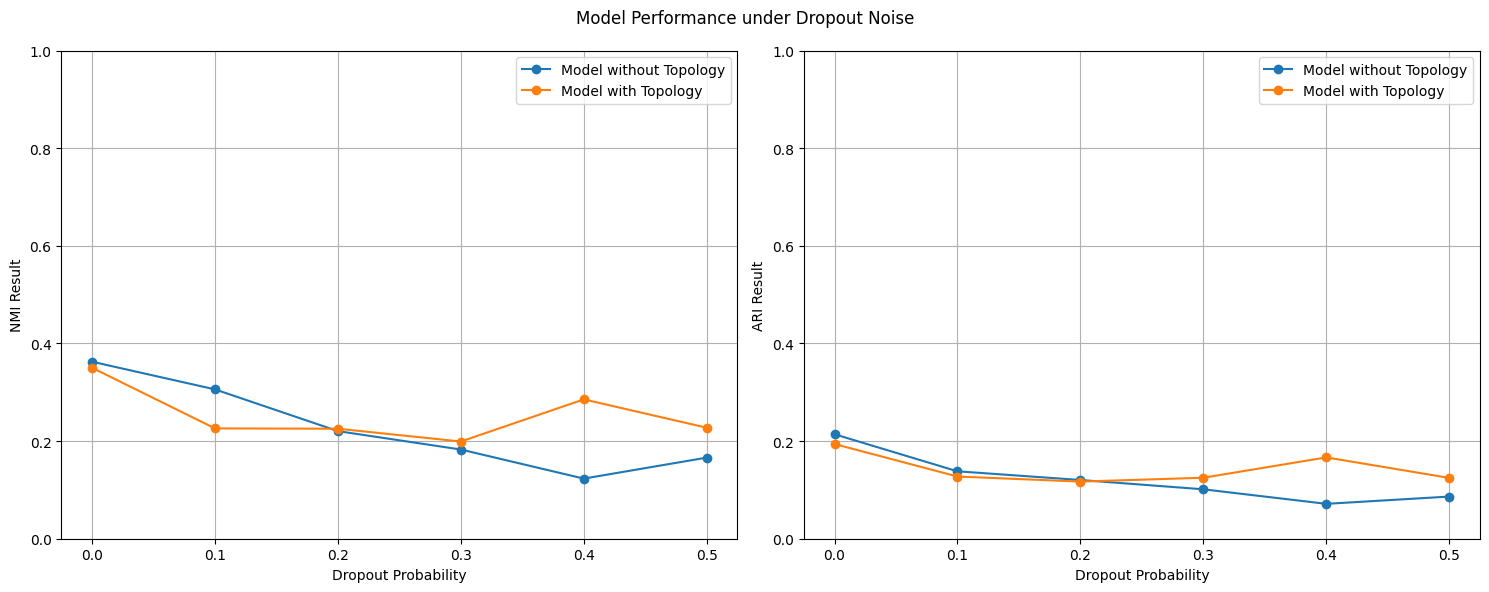

In [ ]:
from utils.perturbation import dropout_event

# Testing with dropout_event first
drop_prob = np.arange(0, 0.55, 0.1)

nmi_scores_1 = []
ari_scores_1 = []

nmi_scores_2 = []
ari_scores_2 = []

for prob in drop_prob:
    x_noisy = dropout_event(x_data, prob).to(device)

    nmi_1, ari_1 = eval_model_with_X(x_noisy.cpu().numpy(), use_topo=False)
    nmi_2, ari_2 = eval_model_with_X(x_noisy.cpu().numpy(), use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)

    print(f"Dropout Noise Level: {prob:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(drop_prob, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('NMI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(drop_prob, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('ARI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.suptitle('Model Performance under Dropout Noise')
plt.tight_layout()
plt.savefig(f"contrastive-sc_{dataset}_dropout_noise_robustness.png")
plt.show()

### B. Testing robustness with Gaussian noise in `X_data`

Epoch 0/1 Summary | Time: 0.02s | Total Epoch loss_: 29.8911
Applying PCA (n_components=60) for Topological manifold reference...
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 30.1845
Dropout Noise Level: 0.00 | Model 1 NMI: 0.4283 | Model 1 ARI: 0.2879 | Model 2 NMI: 0.3511 | Model 2 ARI: 0.2058
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 30.1600
Applying PCA (n_components=60) for Topological manifold reference...
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 30.2360
Dropout Noise Level: 0.10 | Model 1 NMI: 0.4200 | Model 1 ARI: 0.2775 | Model 2 NMI: 0.3167 | Model 2 ARI: 0.1985
Epoch 0/1 Summary | Time: 0.03s | Total Epoch loss_: 30.1185
Applying PCA (n_components=60) for Topological manifold reference...
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 29.6391
Dropout Noise Level: 0.20 | Model 1 NMI: 0.4241 | Model 1 ARI: 0.2671 | Model 2 NMI: 0.3858 | Model 2 ARI: 0.2304
Epoch 0/1 Summary | Time: 0.04s | Total Epoch loss_: 29.9897
Applying PCA (n_componen

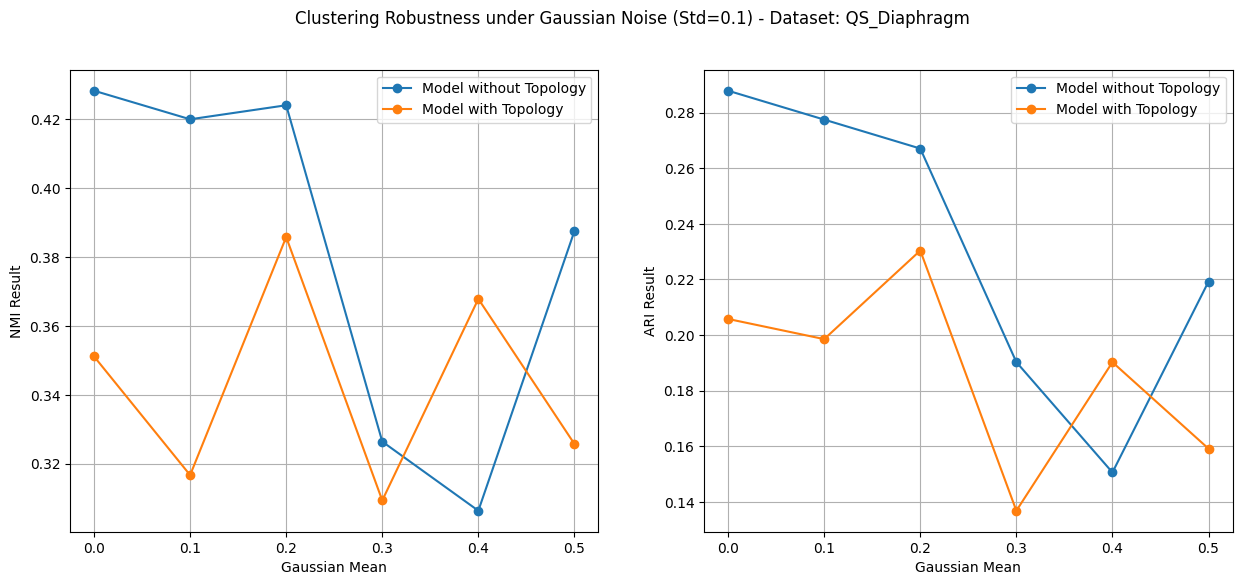

In [ ]:
from utils.perturbation import gaussian_noise_event

# Testing with dropout_event first
STD_GAUSSIAN = 0.1
gaussian_mean = np.arange(0, 0.6, 0.1)

nmi_scores_1 = []
ari_scores_1 = []

nmi_scores_2 = []
ari_scores_2 = []

for mean in gaussian_mean:
    x_noisy = gaussian_noise_event(x_data, mean, std=0.1)

    nmi_1, ari_1 = eval_model_with_X(x_noisy.cpu().numpy(), use_topo=False)
    nmi_2, ari_2 = eval_model_with_X(x_noisy.cpu().numpy(), use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)

    print(f"Dropout Noise Level: {mean:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(gaussian_mean, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean')
plt.ylabel('NMI Result')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(gaussian_mean, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean')
plt.ylabel('ARI Result')
plt.legend()
plt.grid()

plt.suptitle(f'Clustering Robustness under Gaussian Noise (Std={STD_GAUSSIAN}) - Dataset: {dataset}')
plt.tight_layout()
plt.savefig(f"contrastive-sc_{dataset}_gaussian_noise_robustness.png")
plt.show()